# cSplineFlow with Detailed Balance in 3D: Learning a Gas-Surface Scattering Kernel

This notebook repeats `crealnvp_surface_detailed_balance_3d.ipynb` with a **neural spline flow** (`csplineflow_db`) instead of cRealNVP. The model has the same interface and training options, so only the model differs.

**Spline flows.** A SplineFlow is built like RealNVP from coupling layers, but every transformed dimension is mapped by a
monotonic **rational-quadratic spline** instead of an affine map `x · exp(s) + t`. The network predicts the `n_bins` bin widths,
bin heights and knot derivatives of the spline from the kept dimensions (and the condition). The spline acts on
`[-tail_bound, tail_bound]` and is the identity outside, so the data should lie (mostly) inside this interval.
A single spline coupling layer can bend a density much more strongly than an affine one (it can, for example, create several
modes in one step), so fewer coupling layers are needed. The price is a higher cost per layer.


A **scattering kernel** `K(v_i → v_r)` is the probability density that a particle hitting a wall with velocity `v_i`
leaves it with velocity `v_r`. For a wall in equilibrium (Maxwellian `M` at wall temperature) the kernel must satisfy
**detailed balance** (DB), a consequence of time-reversibility:

`|n_i| · M(v_i) · K(v_i → v_r)  =  |n_r| · M(v_r) · K(−v_r → −v_i)`

The conditional flow `q(v_r | v_i)` learns `K` from samples. The DB condition is added as an **additional physical loss**
(`SurfaceDBLoss`), which can be evaluated on arbitrary pairs `(v_i, v_r)`, without any knowledge of the true kernel, only of `M`.

**Test problem:** the Cercignani-Lampis (CL) kernel with accommodation coefficients `α_t = 0.5`, `α_n = 0.6`.
It is known analytically and satisfies DB exactly, so the learned kernel can be compared with the exact one.
The velocity is 3D, `v = (t₁, t₂, n)`: two tangential components and the wall-normal component; units: `σ = 1`.

| Section | Content |
|---|---|
| 2 | CL kernel, abstract variables and the DB data format |
| 3 | Data: few "MD" pairs and many DB points |
| 4 | cSplineFlow with NLL only (baseline) |
| 5 | cSplineFlow with NLL + DB loss |
| 6 | Comparison with the exact kernel |
| 7 | Physical check: equilibrium is preserved |
| 8 | How much data does the DB loss save? |

> **Disclaimer:** The models in this notebook are illustrative examples, not optimized results. Architectures, hyperparameters and training settings were chosen to keep the runtime short, not to reach maximum accuracy. The reported accuracies are therefore not the best achievable with this approach; there is most likely considerable room for improvement, e.g. through tuning of the number of coupling layers and bins, the network size, learning rate (schedule), batch size, number of epochs, DB-weight schedule and number of DB points.

> **Requirements:** `scipy`, `matplotlib`.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from scipy import stats

from neuraldist.generative_model.registry import build_model
import neuraldist.generative_model.splineflow.csplineflow_db # Import registers "csplineflow_db"
from neuraldist.losses import DBWeightScheduler, LinearRampWeight, SurfaceDBLoss
from neuraldist.training import fit_model

tf.keras.utils.set_random_seed(0)
rng = np.random.default_rng(0)

I0000 00:00:1794856041.799339   45198 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794856041.847022   45198 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794856043.416246   45198 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. The Cercignani-Lampis kernel, abstract variables and the DB data format

**Exact kernel (physical space).** Tangential (each of the two components, independent): Gaussian with mean `(1 − α_t)·t_i`
and variance `α_t(2 − α_t)`. Normal: the reflected normal speed `u_r = n_r > 0` follows a Rice distribution with
`ν = √(1−α_n)·u_i` and `s = √α_n` (`u_i = |n_i|`).

**Abstract variables.** A flow lives on all of ℝ³, but the outgoing normal velocity must be positive. The model therefore works in
`y = (t₁, t₂, log u)`. Its density is related to the physical one by the Jacobian: `q_phys = q_abs · |∂y/∂v|`, i.e.
`log q_phys = log q_abs − log u_r`. This is exactly what the data entries `log_det_jacobian_fwd / _bwd` carry.

**DB data entries** (per pair, all in abstract variables; the reversed pair is `(−v_r → −v_i)`):

| key | meaning |
|---|---|
| `v_i`, `v_r` | condition and target of the forward pair (shape `(N, 3)`) |
| `v_i_bwd`, `v_r_bwd` | condition and target of the reversed pair |
| `log_det_jacobian_fwd/_bwd` | `−log u` of the respective target |
| `log_M_i`, `log_M_r` | `log(|n|·M(v))`, the flux-weighted wall Maxwellian |

`SurfaceDBLoss.make_db_data(t_i, u_i, t_r, u_r)` builds exactly these entries from physical pairs.

In [2]:
ALPHA_T, ALPHA_N = 0.5, 0.6
RHO = 1 - ALPHA_T                  # tangential memory
VAR_T = ALPHA_T * (2 - ALPHA_T)    # tangential variance


def reflect(t_i, u_i, rng):
    """Draw (t_r, u_r) from the exact CL kernel. t has shape (N, 2), u shape (N,)."""
    z = rng.standard_normal((len(u_i), 4))
    t_r = RHO * t_i + np.sqrt(VAR_T) * z[:, :2]
    u_r = np.sqrt((np.sqrt(1 - ALPHA_N) * u_i + np.sqrt(ALPHA_N) * z[:, 2]) ** 2 + ALPHA_N * z[:, 3] ** 2)
    return t_r, u_r


def log_kernel_phys(t_r, u_r, t_i, u_i):
    """Exact log K(v_r | v_i) in physical space."""
    s = np.sqrt(ALPHA_N)
    nu = np.sqrt(1 - ALPHA_N) * u_i
    return stats.norm.logpdf(t_r, RHO * t_i, np.sqrt(VAR_T)).sum(axis=1) + stats.rice.logpdf(u_r, nu / s, scale=s)


def exact_log_q_abs(t_r, u_r, t_i, u_i):
    """Exact log density of y_r = (t_r, log u_r) given v_i (what the flow is trained to approximate)."""
    return log_kernel_phys(t_r, u_r, t_i, u_i) + np.log(u_r)


# wall Maxwellian with kT = m = 1; SurfaceDBLoss builds the DB data in the abstract variables (t, log u)
surface_db = SurfaceDBLoss(mass=1.0, kT=1.0)
log_M = surface_db.log_weight              # log(|n| · M(v))
pair_arrays = surface_db.make_db_data      # pairs (t_i, u_i, t_r, u_r) in physical variables -> dict of abstract arrays

### Sanity check of the exact kernel

For arbitrary pairs the DB residual of the exact kernel must vanish, and
particles entering with the equilibrium flux distribution must leave with the same distribution.

In [3]:
# DB residual at arbitrary pairs (v_i, v_r)
t_i, t_r = rng.normal(0, 1.3, (5000, 2)), rng.normal(0, 1.3, (5000, 2))
u_i, u_r = rng.uniform(0.1, 3.5, 5000), rng.uniform(0.1, 3.5, 5000)
lhs = log_kernel_phys(t_r, u_r, t_i, u_i) + log_M(t_i, u_i)
rhs = log_kernel_phys(-t_i, u_i, -t_r, u_r) + log_M(t_r, u_r)
print(f"max |DB residual| of the exact kernel: {np.abs(lhs - rhs).max():.1e}")

# equilibrium preservation: flux-weighted Maxwellian in -> same distribution out
n = 200_000
t_in, u_in = rng.standard_normal((n, 2)), rng.rayleigh(1.0, n)   # flux-weighted: t ~ N(0, I), |n| ~ Rayleigh(1)
t_out, u_out = reflect(t_in, u_in, rng)
print(f"reflected t: mean {t_out.mean(axis=0).round(3)}, std {t_out.std(axis=0).round(3)} (target 0, 1) | "
      f"KS(u, Rayleigh) = {stats.kstest(u_out, stats.rayleigh().cdf).statistic:.4f}")

max |DB residual| of the exact kernel: 1.4e-14
reflected t: mean [-0.002 -0.001], std [1.    0.999] (target 0, 1) | KS(u, Rayleigh) = 0.0019


## 3. Data

- **"MD" data:** only a few pairs from the true kernel, with incident velocities from the flux-weighted equilibrium Maxwellian.
- **DB points:** many *arbitrary* pairs `(v_i, v_r)`. DB holds for every pair, so the points do not need to come from the true kernel.
  They only require the known wall distribution `M`.

`fit_model` combines the MD pairs and the DB points internally; the small MD set is cycled so that both are used in every step.

In [4]:
N_MD, N_DB, BATCH = 300, 4096, 256


def md_pairs(n):
    """Pairs from the true kernel; incidence = flux-weighted equilibrium Maxwellian."""
    t_i, u_i = rng.standard_normal((n, 2)), rng.rayleigh(1.0, n)
    return (t_i, u_i, *reflect(t_i, u_i, rng))


def broad_pairs(n):
    """Pairs from the true kernel with a broader incidence distribution (also covers the tails)."""
    t_i, u_i = rng.normal(0, 1.5, (n, 2)), rng.uniform(0.1, 3.5, n)
    return (t_i, u_i, *reflect(t_i, u_i, rng))


def random_pairs(n):
    """Arbitrary pairs: no kernel needed, DB constrains the model everywhere."""
    return (rng.normal(0, 1.5, (n, 2)), rng.uniform(0.1, 3.5, n),
            rng.normal(0, 1.5, (n, 2)), rng.uniform(0.1, 3.5, n))


md_data = pair_arrays(*md_pairs(N_MD))
db_data = pair_arrays(*random_pairs(N_DB))
print(f"MD pairs: {N_MD} | DB points: {N_DB}")
print({k: v.shape for k, v in db_data.items()})

MD pairs: 300 | DB points: 4096
{'v_i': (4096, 3), 'v_r': (4096, 3), 'v_i_bwd': (4096, 3), 'v_r_bwd': (4096, 3), 'log_det_jacobian_fwd': (4096,), 'log_det_jacobian_bwd': (4096,), 'log_M_i': (4096,), 'log_M_r': (4096,)}


### Evaluation helper

Three numbers, all measured against the exact kernel on **fresh** samples:
- `KL_md`: `KL(p ‖ q)` for incident velocities like the training data,
- `KL_broad`: the same for a broader incidence distribution (tests the tails),
- `DB_rms`: root-mean-square DB residual of the model on arbitrary pairs (0 = perfect).

In [5]:
def evaluate(model):
    out = {}
    for tag, pairs in [("md", md_pairs(5000)), ("broad", broad_pairs(5000))]:
        t_i, u_i, t_r, u_r = pairs
        a = pair_arrays(*pairs)
        logq = model.log_prob(a["v_r"], a["v_i"]).numpy()
        out[f"KL_{tag}"] = float(np.mean(exact_log_q_abs(t_r, u_r, t_i, u_i) - logq))

    a = pair_arrays(*random_pairs(5000))
    lq_f = model.log_prob(a["v_r"], a["v_i"]).numpy()
    lq_b = model.log_prob(a["v_r_bwd"], a["v_i_bwd"]).numpy()
    diff = (lq_f + a["log_det_jacobian_fwd"] + a["log_M_i"]) - (lq_b + a["log_det_jacobian_bwd"] + a["log_M_r"])
    out["DB_rms"] = float(np.sqrt(np.mean(diff**2)))
    return out


def train(md_data, use_db, epochs=60, weight=1.0, seed=0):
    tf.keras.utils.set_random_seed(seed)
    # abstract variables (t, log u) lie well inside [-5, 5]: the splines cover the whole data range
    model = build_model("csplineflow_db", x_dim=3, cond_dim=3, n_coupling=4, n_bins=8, tail_bound=5.0, symmetric=False)
    steps = N_DB // BATCH
    common = dict(batch_size=BATCH, epochs=epochs, steps_per_epoch=steps)
    if use_db:
        history = fit_model(model, md_data["v_r"], md_data["v_i"], db_data=db_data, **common,
                            compile_kwargs={"db_loss": SurfaceDBLoss(epoch_weighting=LinearRampWeight(0.0, weight, 20))},
                            callbacks=[DBWeightScheduler()])
    else:
        history = fit_model(model, md_data["v_r"], md_data["v_i"], **common)
    return model, history

## 4. Baseline: cSplineFlow with NLL only

The condition is the incident velocity in abstract variables `(t₁_i, t₂_i, log u_i)`, the target is `(t₁_r, t₂_r, log u_r)`.
With only the few MD pairs, the flow has nothing but the NLL to learn from.

In [6]:
flow_nll, hist_nll = train(md_data, use_db=False)
print({k: round(v[-1], 3) for k, v in hist_nll.history.items() if k in ("loss", "nll_fwd")})

E0000 00:00:1794856044.364406   45198 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


{'loss': 0.889, 'nll_fwd': 0.889}


## 5. cSplineFlow with NLL + DB loss

`SurfaceDBLoss` penalizes `[log q(v_r|v_i) + log J_fwd + log M_i] − [log q(−v_i|−v_r) + log J_bwd + log M_r]` squared, on the DB points.
Its weight is ramped up from 0 to 1 over 20 epochs by `DBWeightScheduler`. The logged `db_acc = mean(exp(−|diff|))`
is a mean Metropolis-Hastings-type acceptance probability (1 = DB satisfied).

{'db_acc': 0.679, 'db_loss': 0.321, 'db_weight': 1.0, 'loss': 2.403, 'nll_fwd': 2.082}


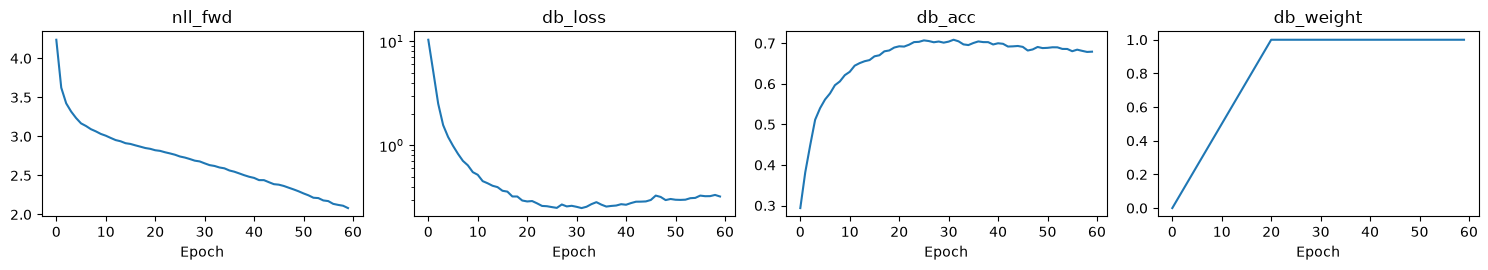

In [7]:
flow_db, hist_db = train(md_data, use_db=True)
print({k: round(v[-1], 3) for k, v in hist_db.history.items() if k in ("loss", "nll_fwd", "db_loss", "db_acc", "db_weight")})

fig, axes = plt.subplots(1, 4, figsize=(15, 2.8))
for ax, key in zip(axes, ["nll_fwd", "db_loss", "db_acc", "db_weight"]):
    ax.plot(hist_db.history[key])
    ax.set(title=key, xlabel="Epoch")
axes[1].set_yscale("log")
fig.tight_layout()
plt.show()

## 6. Comparison with the exact kernel

In [8]:
models = {"NLL only": flow_nll, "NLL + DB": flow_db}
scores = {name: evaluate(m) for name, m in models.items()}

print(f"{'model':10s} | {'KL_md':>9s} | {'KL_broad':>9s} | {'DB_rms':>9s}")
for name, s in scores.items():
    print(f"{name:10s} | {s['KL_md']:9.3f} | {s['KL_broad']:9.3f} | {s['DB_rms']:9.3f}")

model      |     KL_md |  KL_broad |    DB_rms
NLL only   |     3.354 |     5.501 |     8.480
NLL + DB   |     0.395 |     0.562 |     1.014


**Observation:** The NLL-only spline flow overfits the 300 MD pairs (KL ≈ 3.4–5.5, DB residual ≈ 8.5), but far less catastrophically than the NLL-only cRealNVP (KL ≈ 90–160, DB residual above 1000). The DB loss again improves the fit by about an order of magnitude (KL ≈ 0.40–0.56, DB residual ≈ 1.0). With the same short, untuned training the DB-regularized spline flow is, however, less accurate than the DB-regularized cRealNVP (KL ≈ 0.13–0.29, DB residual ≈ 0.8). Neither the architecture nor the training (epochs, learning rate, DB-weight schedule, number of DB points) was tuned for the spline flow.

### Detailed balance, left side vs. right side

In log form, the DB equation for a pair `(v_i, v_r)` reads

`log q(v_r | v_i) + log J_fwd + log M_i   =   log q(−v_i | −v_r) + log J_bwd + log M_r`

(`log J` are the Jacobian terms of the abstract variables, `log M` includes the flux factor `|n|`.)
Each point below is one pair, with the **left side on the x-axis** and the **right side on the y-axis**.
If detailed balance holds, all points lie on the diagonal. Two sets of pairs are shown: arbitrary pairs (the points the DB loss is trained on)
and pairs drawn from the true kernel (where the probability mass is). In the first figure, points outside the plotted window are not drawn but counted; the second figure shows the same arbitrary pairs on a symmetric-log scale without cutting anything off.

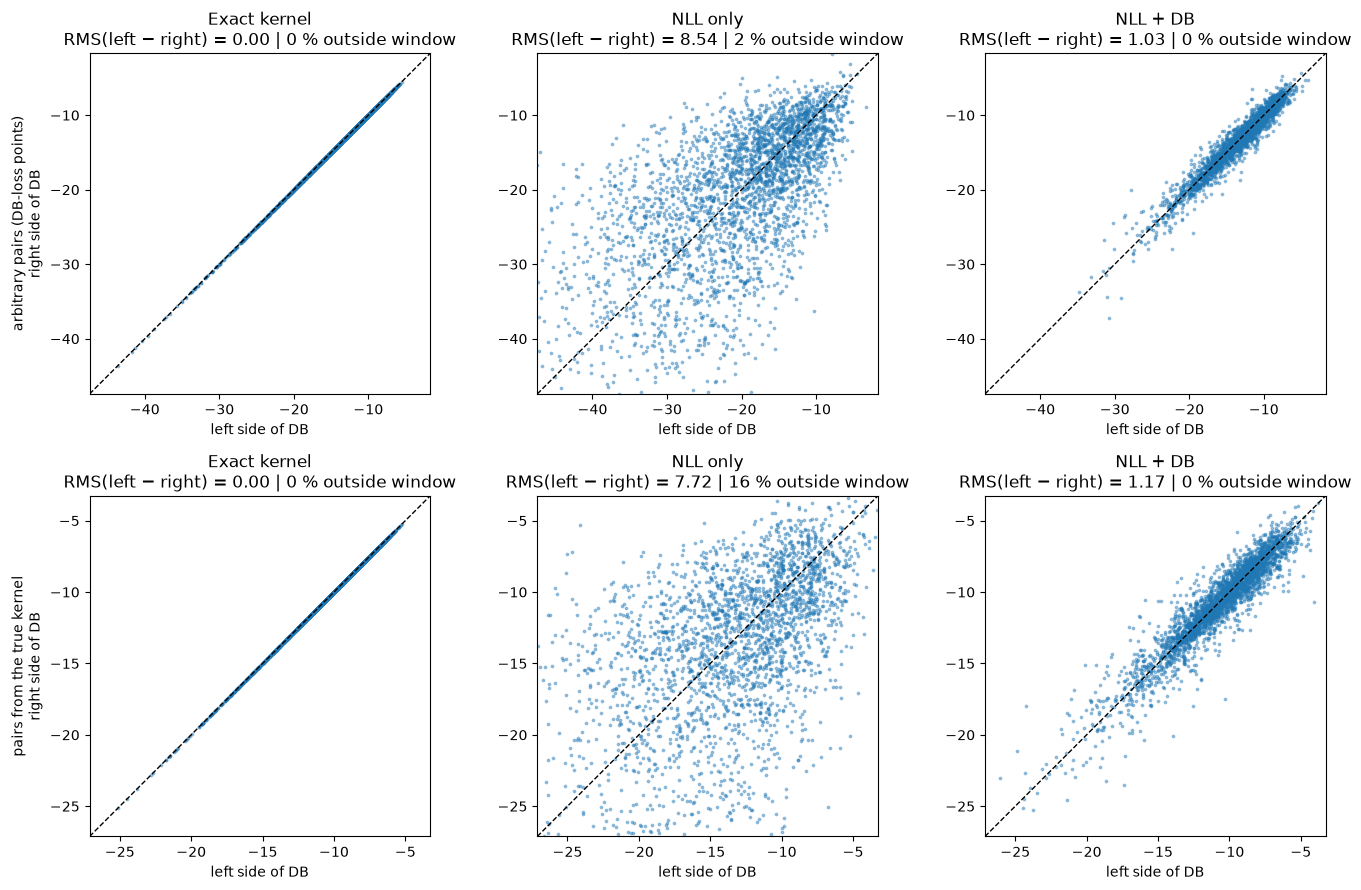

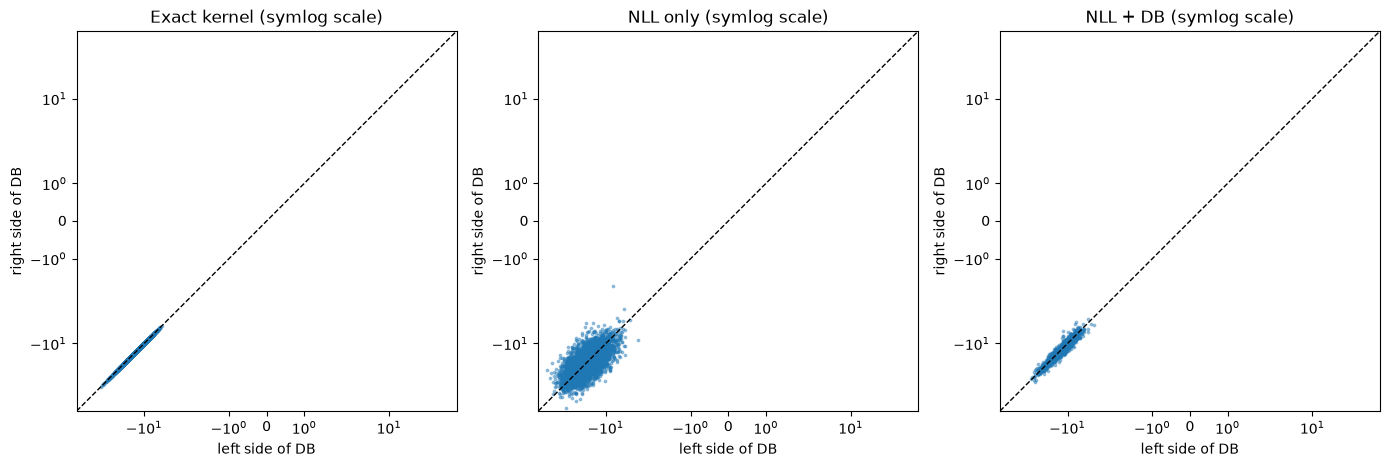

In [9]:
def db_sides(model, pairs):
    """Left and right side of the DB equation (log form) of a model for physical pairs (t_i, u_i, t_r, u_r)."""
    a = pair_arrays(*pairs)
    lhs = model.log_prob(a["v_r"], a["v_i"]).numpy() + a["log_det_jacobian_fwd"] + a["log_M_i"]
    rhs = model.log_prob(a["v_r_bwd"], a["v_i_bwd"]).numpy() + a["log_det_jacobian_bwd"] + a["log_M_r"]
    return lhs, rhs


def db_sides_exact(pairs):
    t_i, u_i, t_r, u_r = pairs
    return (log_kernel_phys(t_r, u_r, t_i, u_i) + log_M(t_i, u_i),
            log_kernel_phys(-t_i, u_i, -t_r, u_r) + log_M(t_r, u_r))


g = np.random.default_rng(123)       # separate generator: leaves the random stream of the other cells untouched
n_plot = 3000
t_i, t_r = g.normal(0, 1.5, (n_plot, 2)), g.normal(0, 1.5, (n_plot, 2))
u_i, u_r = g.uniform(0.1, 3.5, n_plot), g.uniform(0.1, 3.5, n_plot)
pair_sets = {"arbitrary pairs (DB-loss points)": (t_i, u_i, t_r, u_r),
             "pairs from the true kernel": (t_i, u_i, *reflect(t_i, u_i, g))}

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for row, (set_name, pairs) in enumerate(pair_sets.items()):
    sides = {"Exact kernel": db_sides_exact(pairs)}
    sides.update({name: db_sides(m, pairs) for name, m in models.items()})

    exact = np.concatenate(sides["Exact kernel"])                  # plotting window from the exact values
    lo, hi = exact.min(), exact.max()
    lo, hi = lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo)

    for ax, (name, (lhs, rhs)) in zip(axes[row], sides.items()):
        inside = (lhs > lo) & (lhs < hi) & (rhs > lo) & (rhs < hi)
        finite = np.isfinite(lhs) & np.isfinite(rhs)
        rms = np.sqrt(np.mean((lhs[finite] - rhs[finite]) ** 2))
        ax.scatter(lhs[inside], rhs[inside], s=3, alpha=0.4)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set(xlim=(lo, hi), ylim=(lo, hi), aspect="equal", xlabel="left side of DB",
               title=f"{name}\nRMS(left − right) = {rms:.2f} | {100 * (1 - inside.mean()):.0f} % outside window")
    axes[row, 0].set_ylabel(f"{set_name}\nright side of DB")
fig.tight_layout()
plt.show()

# the same arbitrary pairs on a symmetric-log scale: no point is cut off, the failure of the NLL-only flow becomes visible
pairs = pair_sets["arbitrary pairs (DB-loss points)"]
sides = {"Exact kernel": db_sides_exact(pairs)}
sides.update({name: db_sides(m, pairs) for name, m in models.items()})
all_vals = np.concatenate([np.concatenate(v) for v in sides.values()])
lim = 1.1 * np.abs(all_vals[np.isfinite(all_vals)]).max()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (name, (lhs, rhs)) in zip(axes, sides.items()):
    ax.scatter(lhs, rhs, s=3, alpha=0.4)
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)
    ax.set(xscale="symlog", yscale="symlog", xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal",
           title=f"{name} (symlog scale)", xlabel="left side of DB", ylabel="right side of DB")
fig.tight_layout()
plt.show()

**Observation:** For the exact kernel all points lie on the diagonal (RMS 0). The NLL-only flow violates detailed balance clearly (RMS ≈ 8): left and right side form a broad cloud that follows the diagonal only loosely, with 2 % (arbitrary pairs) and 16 % (pairs from the true kernel) of the points outside the window. In the symlog plot the cloud stays within about one order of magnitude, unlike the NLL-only cRealNVP whose log-densities reach −10⁴. The DB-regularized flow scatters closely around the diagonal (RMS ≈ 1.0–1.2); the scatter is widest for very negative values, i.e. for improbable pairs in the tails, where the model is least constrained.

### Conditional distribution for one incident velocity

For a fixed incident velocity the reflected velocity is plotted as 2D histograms of two projections,
`(t₁_r, u_r)` and `(t₂_r, u_r)`, for samples from the exact kernel and from both flows (same colour scale).

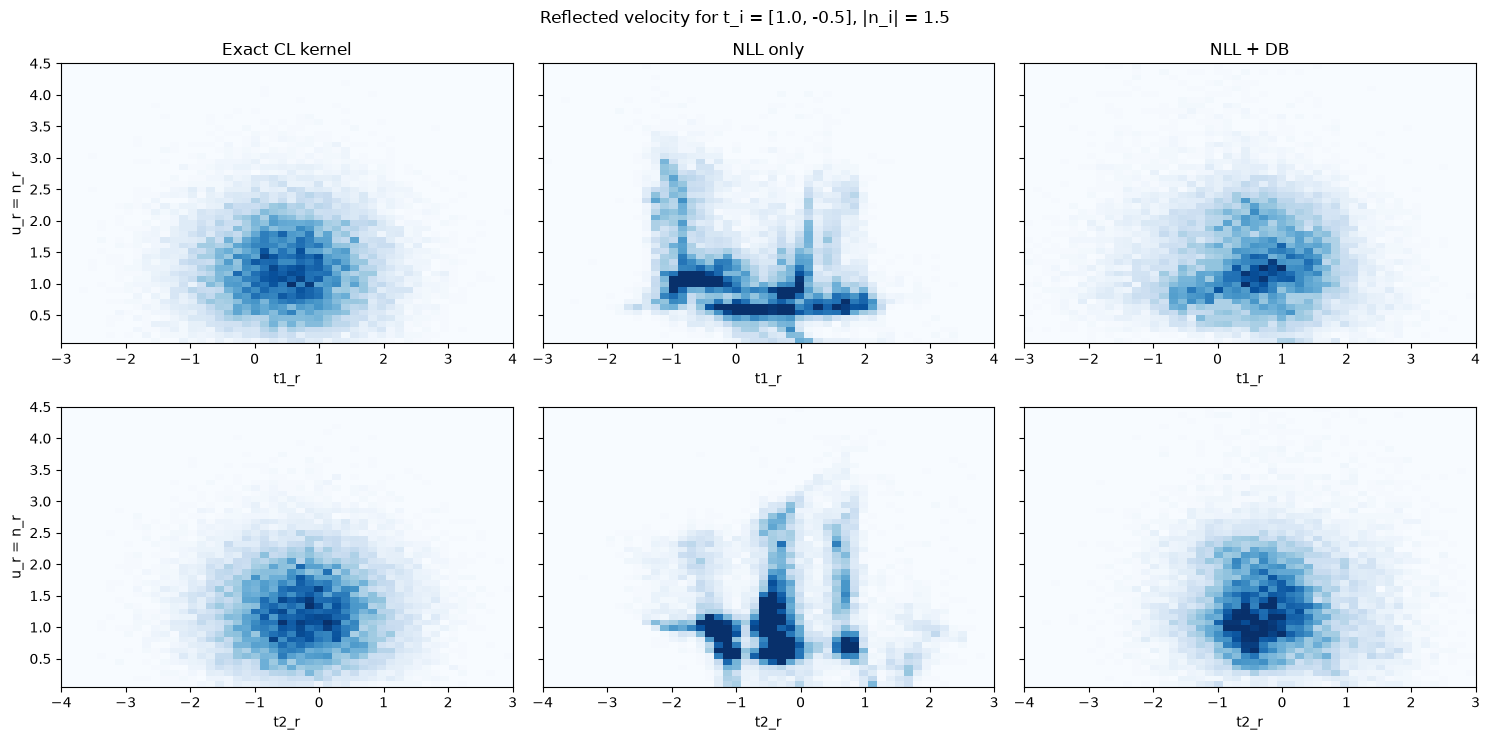

In [10]:
def reflected(model, t_i, u_i, n=2000):
    """Samples of the reflected velocity (t_r, u_r) for incident velocities t_i (B, 2), u_i (B,)."""
    cond = np.column_stack([t_i, np.log(u_i)]).astype("float32")
    y = model.sample(n, cond=cond).numpy()                           # (B, n, 3) in abstract variables
    return y[..., :2], np.exp(np.clip(y[..., 2], -20, 20))           # t_r (B, n, 2), u_r (B, n)


t_i0, u_i0, n_vis = np.array([[1.0, -0.5]]), np.array([1.5]), 20_000
samples = {"Exact CL kernel": reflect(np.repeat(t_i0, n_vis, axis=0), np.repeat(u_i0, n_vis), rng)}
for name, m in models.items():
    t_r, u_r = reflected(m, t_i0, u_i0, n_vis)
    samples[name] = (t_r[0], u_r[0])

ranges = {0: [[-3, 4], [0.05, 4.5]], 1: [[-4, 3], [0.05, 4.5]]}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for row, comp in enumerate([0, 1]):
    vmax = np.histogram2d(samples["Exact CL kernel"][0][:, comp], samples["Exact CL kernel"][1],
                          bins=50, range=ranges[comp], density=True)[0].max()
    for ax, (title, (t_r, u_r)) in zip(axes[row], samples.items()):
        ok = np.isfinite(t_r[:, comp]) & np.isfinite(u_r)
        h, xe, ye = np.histogram2d(t_r[ok, comp], u_r[ok], bins=50, range=ranges[comp], density=True)
        ax.pcolormesh(xe, ye, np.minimum(h.T, vmax), cmap="Blues", vmin=0, vmax=vmax)
        ax.set(title=title if row == 0 else "", xlabel=f"t{comp + 1}_r")
    axes[row, 0].set_ylabel("u_r = n_r")
fig.suptitle(f"Reflected velocity for t_i = {t_i0[0].tolist()}, |n_i| = {u_i0[0]}")
fig.tight_layout()
plt.show()

**Observation:** The NLL-only flow memorizes the 300 training pairs and produces stripes and filaments in both projections. The flow with DB loss reproduces a single lobe at the right position and of about the right width, with some lumpy substructure that the exact kernel does not have.

### Moments as a function of the incident velocity

Reflected tangential means (exact: `(1 − α_t)·t_i`) and reflected normal median (exact: Rice distribution).

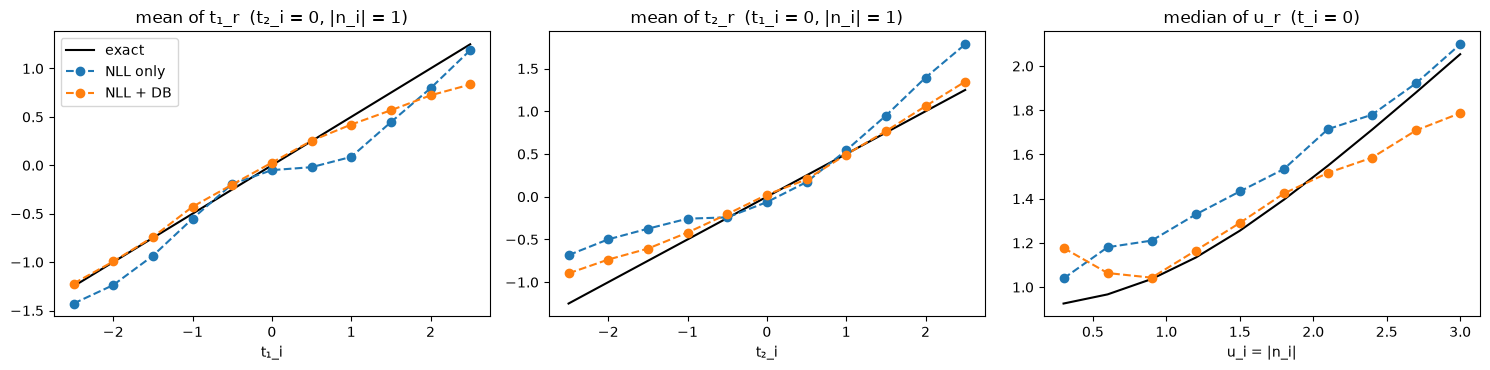

In [11]:
t_axis = np.linspace(-2.5, 2.5, 11)
u_axis = np.linspace(0.3, 3.0, 10)
zeros_t, zeros_u = np.zeros_like(t_axis), np.zeros_like(u_axis)
s_ = np.sqrt(ALPHA_N)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(t_axis, RHO * t_axis, "k", label="exact")
axes[1].plot(t_axis, RHO * t_axis, "k", label="exact")
axes[2].plot(u_axis, stats.rice.median(np.sqrt(1 - ALPHA_N) * u_axis / s_, scale=s_), "k", label="exact")
for name, m in models.items():
    t_r, _ = reflected(m, np.column_stack([t_axis, zeros_t]), np.ones_like(t_axis))      # vary t₁_i
    axes[0].plot(t_axis, t_r[..., 0].mean(axis=1), "o--", label=name)
    t_r, _ = reflected(m, np.column_stack([zeros_t, t_axis]), np.ones_like(t_axis))      # vary t₂_i
    axes[1].plot(t_axis, t_r[..., 1].mean(axis=1), "o--", label=name)
    _, u_r = reflected(m, np.column_stack([zeros_u, zeros_u]), u_axis)                    # vary |n_i|
    axes[2].plot(u_axis, np.median(u_r, axis=1), "o--", label=name)
axes[0].set(title="mean of t₁_r  (t₂_i = 0, |n_i| = 1)", xlabel="t₁_i")
axes[1].set(title="mean of t₂_r  (t₁_i = 0, |n_i| = 1)", xlabel="t₂_i")
axes[2].set(title="median of u_r  (t_i = 0)", xlabel="u_i = |n_i|")
axes[0].legend()
fig.tight_layout()
plt.show()

**Observation:** The tangential means of the DB flow follow the exact linear dependence `(1 − α_t)·t_i` for `|t_i| ≲ 1.5`, but are attenuated for large incident tangential velocities (e.g. 0.83 instead of 1.25 at `t₁_i = 2.5`, and too small in magnitude for negative `t₂_i`). The NLL-only flow is biased in a less regular way (a dip of the `t₁_r` mean for `t₁_i ≈ 0…1`, flattening for negative `t₂_i`). For the normal median the DB flow is correct between `|n_i| ≈ 0.9` and 2, too high for small and about 13 % too low at `|n_i| = 3` (cRealNVP + DB: about 30 % too low), whereas the NLL-only flow is too high over most of the range. Large normal velocities are rare in the equilibrium MD data and are only constrained indirectly by the DB term.

## 7. Physical check: equilibrium is preserved

If particles arrive with the equilibrium flux distribution (`t ~ N(0, I)`, `|n| ~ Rayleigh(1)`), a kernel in detailed balance
returns the **same** distribution. This is checked here for the learned kernels, one reflected sample per incident particle.
(The exact kernel gives KS ≈ 0.002 for the same test.)

In [12]:
n = 20_000
t_eq, u_eq = rng.standard_normal((n, 2)), rng.rayleigh(1.0, n)
cond_eq = np.column_stack([t_eq, np.log(u_eq)]).astype("float32")

print(f"{'model':10s} | {'finite':>7s} | {'KS(t1)':>7s} | {'KS(t2)':>7s} | {'KS(u, Rayleigh)':>16s}")
for name, m in models.items():
    y = m.sample(1, cond=cond_eq).numpy()[:, 0, :]
    t1, t2, u = y[:, 0], y[:, 1], np.exp(np.clip(y[:, 2], -20, 20))
    ok = np.isfinite(t1) & np.isfinite(t2) & np.isfinite(u)
    ks = lambda a, cdf: stats.kstest(a[ok], cdf).statistic
    print(f"{name:10s} | {ok.mean():7.2f} | {ks(t1, stats.norm.cdf):7.3f} | {ks(t2, stats.norm.cdf):7.3f} | "
          f"{ks(u, stats.rayleigh().cdf):16.3f}")

model      |  finite |  KS(t1) |  KS(t2) |  KS(u, Rayleigh)


NLL only   |    1.00 |   0.044 |   0.073 |            0.044


NLL + DB   |    1.00 |   0.025 |   0.038 |            0.019


**Observation:** The DB flow preserves equilibrium about twice as well as the NLL-only flow (KS distances ≈ 0.02–0.04 versus 0.04–0.07), in all three velocity components.

## 8. How much data does the DB loss save?

The DB term acts as a physics-based regularizer: it is most valuable when MD data is scarce. The sweep trains both variants
for different numbers of MD pairs (same number of optimizer steps, same DB points).

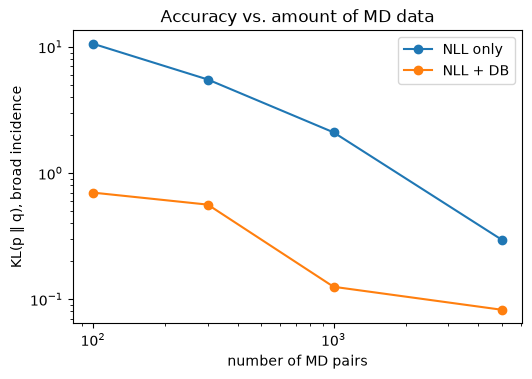

MD pairs |  KL_broad NLL only |  KL_broad NLL + DB
     100 |             10.561 |              0.699
     300 |              5.501 |              0.562
    1000 |              2.098 |              0.125
    5000 |              0.296 |              0.083


In [13]:
sweep = {N_MD: {name: scores[name] for name in models}}
for n_md in [100, 1000, 5000]:
    data = pair_arrays(*md_pairs(n_md))
    sweep[n_md] = {}
    for name, use_db in [("NLL only", False), ("NLL + DB", True)]:
        m, _ = train(data, use_db)
        sweep[n_md][name] = evaluate(m)

sizes = sorted(sweep)
fig, ax = plt.subplots(figsize=(5.8, 3.8))
for name in ["NLL only", "NLL + DB"]:
    ax.plot(sizes, [sweep[n][name]["KL_broad"] for n in sizes], "o-", label=name)
ax.set(xscale="log", yscale="log", xlabel="number of MD pairs", ylabel="KL(p ‖ q), broad incidence",
       title="Accuracy vs. amount of MD data")
ax.legend()
plt.show()

print(f"{'MD pairs':>8s} | {'KL_broad NLL only':>18s} | {'KL_broad NLL + DB':>18s}")
for n_md in sizes:
    print(f"{n_md:8d} | {sweep[n_md]['NLL only']['KL_broad']:18.3f} | {sweep[n_md]['NLL + DB']['KL_broad']:18.3f}")

**Observation:** The DB loss lowers the KL by a factor of about 15 at 100 MD pairs, 10 at 300 pairs, 17 at 1000 pairs and still about 3.5 at 5000 pairs. In contrast to cRealNVP, the NLL-only spline flow does not fail catastrophically for small data sets: its KL decreases smoothly with the number of MD pairs (10.6 → 0.30). This is a single run per setting: read the trend, not the individual numbers. The absolute KL values of both variants could be lowered further by tuning; the sweep is meant to show the relative effect of the DB loss, not the best achievable accuracy.